# Beach bird detection — CNN

Run the cells from top to bottom. The notebook trains the CNN, saves `cnn.pt` in this folder, and prints validation mAP@0.5 from that model.

**mAP@0.5** means a box counts only when it covers at least half a real bird. The 0.5 is that overlap. The score is whatever training prints.

In [1]:
%matplotlib inline
import math
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

ROOT = Path.cwd().resolve()
if not (ROOT / "dataset").is_dir():
    ROOT = ROOT.parent
DATA = ROOT / "dataset" / "beach-bird" / "Beach Bird Detection Dataset v1.0"
IMG, STRIDE = 512, 4
OUT = IMG // STRIDE
EPOCHS = 8  # shortcut: 8 epochs finishes on a laptop; raise this for a longer run

def load_split(split):
    items = []
    for name in sorted(os.listdir(DATA / "labels" / split)):
        if not name.endswith(".txt"):
            continue
        boxes = []
        for line in open(DATA / "labels" / split / name):
            line = line.strip()
            if not line:
                continue
            _, cx, cy, w, h = [float(v) for v in line.split()]
            cx, cy, w, h = cx * IMG, cy * IMG, w * IMG, h * IMG
            boxes.append([cx - w / 2, cy - h / 2, w, h])
        items.append((str(DATA / "images" / split / name.replace(".txt", ".jpg")),
                      np.array(boxes, np.float32).reshape(-1, 4)))
    return items

train, val = load_split("train"), load_split("val")
print(len(train), "train images,", len(val), "val images")

1369 train images, 291 val images


## Network

In [2]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, 2, 1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
        self.enc = nn.Sequential(block(3, 16), block(16, 32), block(32, 64), block(64, 128))
        self.dec = nn.Sequential(
            nn.Upsample(scale_factor=2), nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2), nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(inplace=True),
        )
        self.hm, self.wh, self.off = nn.Conv2d(32, 1, 1), nn.Conv2d(32, 2, 1), nn.Conv2d(32, 2, 1)
        nn.init.constant_(self.hm.bias, -2.0)

    def forward(self, x):
        x = self.dec(self.enc(x))
        return self.hm(x), self.wh(x), self.off(x)

def read_tensor(path):
    im = Image.open(path).convert("RGB").resize((IMG, IMG))
    return torch.from_numpy(np.array(im, np.float32) / 255).permute(2, 0, 1)

model = Net()
print(sum(p.numel() for p in model.parameters()), "parameters")

190341 parameters


## Train

Each bird is a blob on the score map. Horizontal flip is the only augmentation. The best epoch is written to `cnn.pt`.

In [3]:
def draw_gaussian(hm, center, radius):
    radius = int(radius)
    x, y = int(center[0]), int(center[1])
    h, w = hm.shape
    sigma = (2 * radius + 1) / 6
    yy, xx = np.ogrid[-radius:radius + 1, -radius:radius + 1]
    gauss = np.exp(-(xx * xx + yy * yy) / (2 * sigma * sigma))
    l, t = min(x, radius), min(y, radius)
    r, b = min(w - x, radius + 1), min(h - y, radius + 1)
    if r <= 0 or b <= 0 or l < 0 or t < 0:
        return
    patch = hm[y - t:y + b, x - l:x + r]
    np.maximum(patch, gauss[radius - t:radius + b, radius - l:radius + r], out=patch)

def make_targets(boxes):
    hm = np.zeros((1, OUT, OUT), np.float32)
    wh = np.zeros((2, OUT, OUT), np.float32)
    off = np.zeros((2, OUT, OUT), np.float32)
    mask = np.zeros((1, OUT, OUT), np.float32)
    for x, y, w, h in boxes:
        cx, cy = (x + w / 2) / STRIDE, (y + h / 2) / STRIDE
        ix, iy = int(cx), int(cy)
        if not (0 <= ix < OUT and 0 <= iy < OUT):
            continue
        draw_gaussian(hm[0], (ix, iy), max(min(w, h) / STRIDE / 3, 1))
        mask[0, iy, ix] = 1
        wh[:, iy, ix] = np.log(np.maximum([w, h], 1e-4) / IMG)
        off[:, iy, ix] = [cx - ix, cy - iy]
    return hm, wh, off, mask

def focal(pred, gt):
    pos, neg = gt.eq(1).float(), gt.lt(1).float()
    pred = pred.clamp(1e-4, 1 - 1e-4)
    loss = -(torch.log(pred) * (1 - pred) ** 2 * pos).sum()
    loss = loss - (torch.log(1 - pred) * pred ** 2 * (1 - gt) ** 4 * neg).sum()
    return loss / pos.sum().clamp(min=1)

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[0] + a[2], b[0] + b[2]), min(a[1] + a[3], b[1] + b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    den = a[2] * a[3] + b[2] * b[3] - inter
    return inter / den if den > 0 else 0

def boxes_from(hm, wh, off, thr=0.02, topk=500):
    score = torch.sigmoid(hm[0])
    keep = (score == F.max_pool2d(score[None, None], 3, 1, 1)[0, 0]) & (score > thr)
    ys, xs = torch.where(keep)
    sc = score[ys, xs]
    if len(sc) > topk:
        sc, idx = sc.topk(topk)
        ys, xs = ys[idx], xs[idx]
    out = []
    for y, x, s in zip(ys, xs, sc):
        bw = math.exp(float(wh[0, y, x])) * IMG
        bh = math.exp(float(wh[1, y, x])) * IMG
        cx = (float(x) + float(off[0, y, x])) * STRIDE
        cy = (float(y) + float(off[1, y, x])) * STRIDE
        out.append(([cx - bw / 2, cy - bh / 2, bw, bh], float(s)))
    return out

def average_precision(records):
    flat, n_gt = [], 0
    for preds, gts in records:
        n_gt += len(gts)
        used = [False] * len(gts)
        for box, s in sorted(preds, key=lambda t: -t[1]):
            best, best_iou = -1, 0.5
            for j, g in enumerate(gts):
                if used[j]:
                    continue
                v = iou(box, g)
                if v >= best_iou:
                    best, best_iou = j, v
            if best >= 0:
                used[best] = True
            flat.append((s, best >= 0))
    flat.sort(key=lambda t: -t[0])
    prec, seen = [], 0
    for i, (_, hit) in enumerate(flat):
        seen += hit
        prec.append(seen / (i + 1))
    for i in range(len(prec) - 2, -1, -1):
        prec[i] = max(prec[i], prec[i + 1])
    return sum(p for (_, hit), p in zip(flat, prec) if hit) / max(n_gt, 1)

@torch.no_grad()
def val_map():
    model.eval()
    records = []
    for s in range(0, len(val), 4):
        batch = val[s:s + 4]
        hm, wh, off = model(torch.stack([read_tensor(p) for p, _ in batch]))
        for i in range(len(batch)):
            records.append((boxes_from(hm[i], wh[i], off[i]), batch[i][1]))
    return average_precision(records)

torch.manual_seed(0)
np.random.seed(0)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
best, best_ep = -1.0, 0
for ep in range(1, EPOCHS + 1):
    model.train()
    order = np.random.permutation(len(train))
    total, n = 0.0, 0
    for s in range(0, len(order), 8):
        xs, hms, whs, offs, ms = [], [], [], [], []
        for i in order[s:s + 8]:
            x, b = read_tensor(train[i][0]), train[i][1].copy()
            if np.random.rand() < 0.5:
                x = torch.flip(x, [-1])
                if len(b):
                    b = np.stack([IMG - b[:, 0] - b[:, 2], b[:, 1], b[:, 2], b[:, 3]], 1)
            hm, wh, off, m = make_targets(b)
            xs.append(x)
            hms.append(torch.from_numpy(hm))
            whs.append(torch.from_numpy(wh))
            offs.append(torch.from_numpy(off))
            ms.append(torch.from_numpy(m))
        x = torch.stack(xs)
        hm, wh, off, m = map(torch.stack, (hms, whs, offs, ms))
        p_hm, p_wh, p_off = model(x)
        loss = focal(p_hm.sigmoid(), hm)
        loss = loss + 0.1 * (F.l1_loss(p_wh, wh, reduction="none") * m).sum() / m.sum().clamp(min=1)
        loss = loss + (F.l1_loss(p_off, off, reduction="none") * m).sum() / m.sum().clamp(min=1)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += float(loss.detach())
        n += 1
    ap = val_map()
    mark = ""
    if ap > best:
        best, best_ep = ap, ep
        torch.save({"state": model.state_dict(), "epoch": ep, "map": ap, "input": IMG}, "cnn.pt")
        mark = "  saved cnn.pt"
    print(f"epoch {ep}  loss {total / n:.3f}  val mAP@0.5 {ap:.3f}{mark}")

print(f"best val mAP@0.5 {best:.3f} at epoch {best_ep}")

epoch 1  loss 3.592  val mAP@0.5 0.014  saved cnn.pt


epoch 2  loss 3.289  val mAP@0.5 0.022  saved cnn.pt


epoch 3  loss 3.168  val mAP@0.5 0.015


epoch 4  loss 3.130  val mAP@0.5 0.032  saved cnn.pt


epoch 5  loss 3.008  val mAP@0.5 0.044  saved cnn.pt


epoch 6  loss 2.988  val mAP@0.5 0.038


epoch 7  loss 2.995  val mAP@0.5 0.065  saved cnn.pt


epoch 8  loss 2.916  val mAP@0.5 0.049
best val mAP@0.5 0.065 at epoch 7


Green is the label. Red is the trained model.

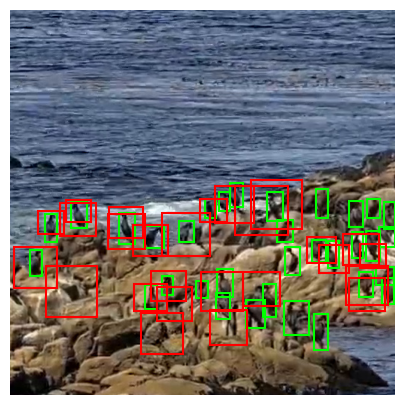

loaded cnn.pt from epoch 7


In [4]:
ckpt = torch.load("cnn.pt", map_location="cpu", weights_only=False)
model.load_state_dict(ckpt["state"])
model.eval()
path, gts = val[0]
with torch.no_grad():
    hm, wh, off = model(read_tensor(path)[None])
preds = boxes_from(hm[0], wh[0], off[0])
im = np.array(Image.open(path).convert("RGB"))
plt.figure(figsize=(5, 5))
plt.imshow(im)
ax = plt.gca()
for x, y, w, h in gts:
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor="lime", lw=1.5))
for (x, y, w, h), s in preds:
    if s < 0.1:
        continue
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor="red", lw=1.5))
plt.axis("off")
plt.show()
print("loaded cnn.pt from epoch", ckpt["epoch"])